# Launch analog EDA

Exploratory look at the built tables in `data/processed/` (see [data_model.md](../docs/data_model.md)). The questions come from the open items in [decisions.md](../docs/decisions.md) and the known issues in [CLAUDE.md](../CLAUDE.md):

1. **Pool:** what's in the analog pool, and what does the `enough_data` rule leave out (survivorship)?
2. **Curve shape:** how do uptake curves differ by therapeutic area and route? Oncology vs. immunology in particular (one area or two for the demo?).
3. **Peak inside Q0–Q20:** how many curves are still climbing at Q20, and does that line up with the COVID enrollment growth?
4. **Bass fits:** what range of p and q does history give, and which fits are weak?
5. **Distortion flags:** how common are they in the usable pool, and do they change the curve?
6. **Seed brands:** the psoriasis prototype analogs and Ibrance.

All curves are **Medicaid** (SDUD) TRx, with the launch quarter = first SDUD quarter (no launch dates are approved yet). Nothing here is rebuilt; it only reads the committed tables.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"

# chart style: thin marks, recessive grid; categorical slots in fixed order (blue, orange, aqua)
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8f8e89"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "grid.linewidth": 0.8, "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 2,
    "legend.frameon": False, "font.size": 9,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
analogs = pd.read_csv(PROCESSED / "analogs.csv", dtype=str, keep_default_na=False)
features = pd.read_csv(PROCESSED / "analog_features.csv")
curves = pd.read_csv(PROCESSED / "launch_curves.csv")
fits = pd.read_csv(PROCESSED / "bass_fits.csv")
history = pd.read_csv(PROCESSED / "indication_history.csv")
enroll = pd.read_csv(PROCESSED / "medicaid_enrollment.csv")

def qnum(period):
    """'2019Q2' -> 2019*4 + 1, so quarters subtract."""
    return int(period[:4]) * 4 + int(period[-1]) - 1

# Therapeutic area from ATC. L (antineoplastic & immunomodulating) is split, because
# oncology and immunology launches behave differently (open question in decisions.md).
ATC1 = {"A": "Alimentary & metabolism", "B": "Blood", "C": "Cardiovascular", "D": "Dermatology",
        "G": "GU & sex hormones", "H": "Systemic hormones", "J": "Anti-infectives", "M": "Musculoskeletal",
        "N": "Nervous system", "P": "Antiparasitic", "R": "Respiratory", "S": "Sensory organs", "V": "Various"}

def area(row):
    broad = row.class_broad if isinstance(row.class_broad, str) else ""
    if broad.startswith(("L01", "L02")):
        return "Oncology"
    if broad.startswith(("L03", "L04")):
        return "Immunology"
    code = row.therapeutic_area[:1] if isinstance(row.therapeutic_area, str) else ""
    return ATC1.get(code, "No ATC class")

features["area"] = features.apply(area, axis=1)
a = analogs.set_index("analog_id")
features["approval_year"] = features.analog_id.map(a["approval date"]).str[:4].astype(int)
features["brand"] = features.analog_id.map(a["brand name"])
features["rx_total"] = pd.to_numeric(features.analog_id.map(a["Rx"]), errors="coerce")
usable_ids = set(features.loc[features.enough_data & ~features.late_launch & ~features.generic_entry_in_window, "analog_id"])
features["usable"] = features.analog_id.isin(usable_ids)
curves = curves.merge(features[["analog_id", "area", "route_group", "usable"]], on="analog_id")
print(f"{len(features)} analogs; usable (checks.md funnel): {len(usable_ids)}")

426 analogs; usable (checks.md funnel): 250


## 1. The pool, and who the rules leave out

`usable` = the end of the `checks.md` funnel: has a launch quarter, not `late_launch`, no generic in Q0–Q12, and `enough_data` (≥ 12 complete quarters, no blank quarter after Q2).

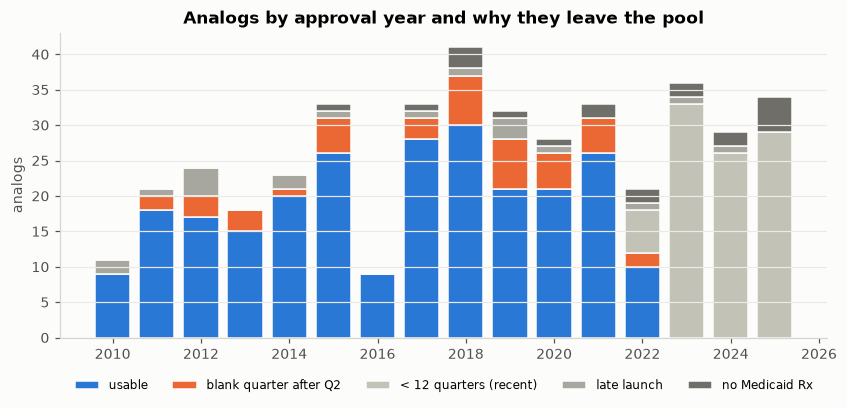

status
usable                    250
< 12 quarters (recent)     94
blank quarter after Q2     43
no Medicaid Rx             20
late launch                19
Name: count, dtype: int64

In [3]:
def drop_reason(r):
    if pd.isna(r.quarters_of_data):
        return "no Medicaid Rx"
    if r.late_launch:
        return "late launch"
    if r.generic_entry_in_window:
        return "generic in Q0-Q12"
    if r.quarters_of_data < 12:
        return "< 12 quarters (recent)"
    if r.blank_quarters_after_q2 > 0:
        return "blank quarter after Q2"
    return "usable"

features["status"] = features.apply(drop_reason, axis=1)
order = ["usable", "blank quarter after Q2", "< 12 quarters (recent)", "late launch", "no Medicaid Rx"]
by_year = features.groupby(["approval_year", "status"]).size().unstack(fill_value=0).reindex(columns=order, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [BLUE, ORANGE, "#c3c2b7", "#a8a79f", "#6f6e69"]
bottom = np.zeros(len(by_year))
for col, c in zip(order, colors):
    ax.bar(by_year.index, by_year[col], bottom=bottom, color=c, width=0.8, edgecolor="#fcfcfb", linewidth=1, label=col)
    bottom += by_year[col].to_numpy()
ax.set_title("Analogs by approval year and why they leave the pool")
ax.set_ylabel("analogs")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8)
ax.grid(axis="x", visible=False)
plt.show()
features.status.value_counts()

Most losses before 2022 are **blank quarters after Q2**, i.e. suppressed (< 11 Rx) or missing quarters mid-curve. Those are small brands, so the usable pool leans towards bigger launches. Check how different they are:

In [4]:
cmp = features[features.status.isin(["usable", "blank quarter after Q2"])]
cmp.groupby("status").agg(analogs=("analog_id", "size"), median_rx=("rx_total", "median"),
                          median_peak_trx=("peak_trx", "median"),
                          pct_oncology=("area", lambda s: round(100 * (s == "Oncology").mean())))

,analogs,median_rx,median_peak_trx,pct_oncology
status,,,,
blank quarter after Q2,43,441.5,57.0,37
usable,250,34367.0,1263.5,25


In [5]:
tab = features.groupby("area").agg(all=("analog_id", "size"), usable=("usable", "sum"),
                                   oral=("route_group", lambda s: (s == "oral").sum()),
                                   sc=("route_group", lambda s: (s == "sc").sum()))
tab["pct_usable"] = (100 * tab.usable / tab["all"]).round()
tab.sort_values("usable", ascending=False)

,all,usable,oral,sc,pct_usable
area,,,,,
Oncology,104,62,97,7,60.0
Nervous system,52,41,46,6,79.0
Alimentary & metabolism,51,34,38,13,67.0
Immunology,51,28,25,26,55.0
Anti-infectives,35,18,34,1,51.0
Blood,26,15,17,9,58.0
Cardiovascular,19,13,14,5,68.0
Respiratory,10,8,6,4,80.0
GU & sex hormones,12,7,11,1,58.0


## 2. Curve shape by therapeutic area and route

Share of peak (TRx ÷ max TRx over Q0–Q20) for usable analogs: each analog a thin gray line, the median in blue with the interquartile band. Areas with ≥ 8 usable analogs.

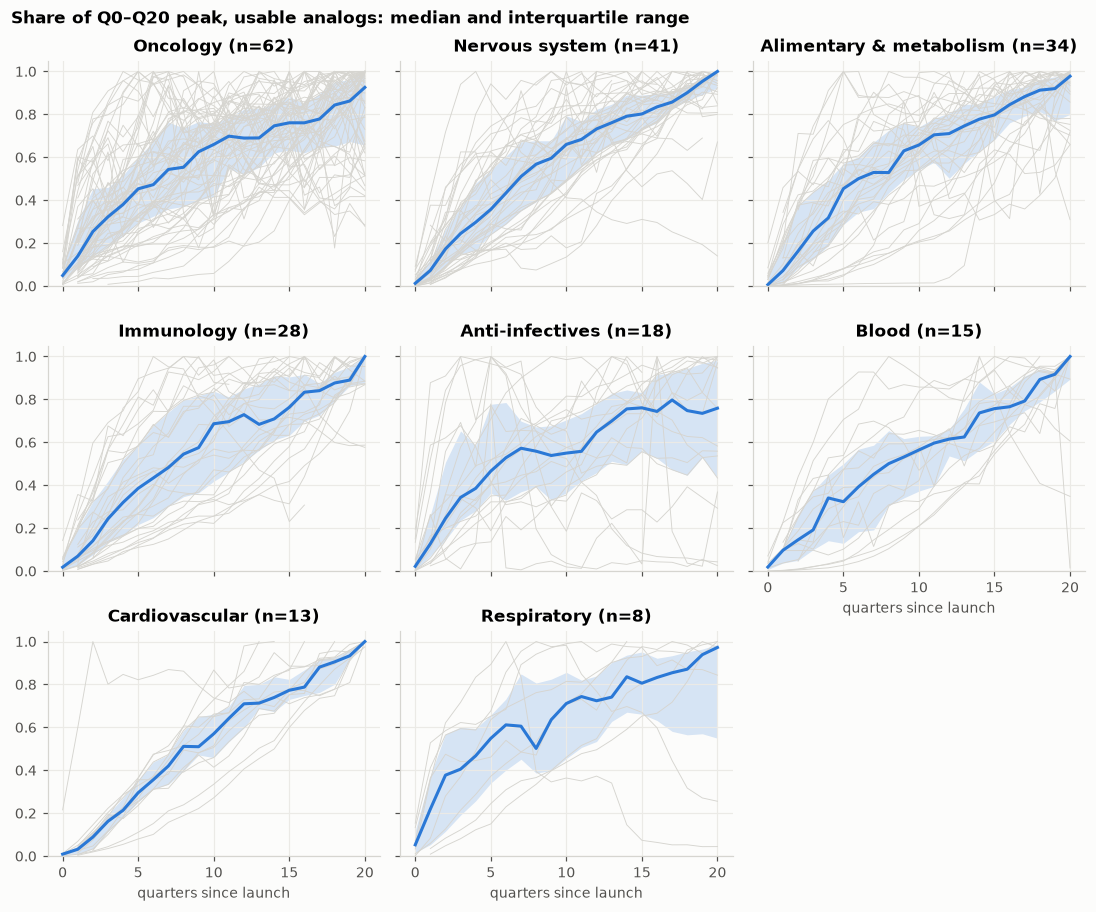

In [6]:
u = curves[curves.usable & ~curves.provisional]
big = u.groupby("area").analog_id.nunique()
big = big[big >= 8].sort_values(ascending=False).index.tolist()

def band(df):
    g = df.groupby("q_since_launch").share_of_peak
    return pd.DataFrame({"median": g.median(), "q25": g.quantile(0.25), "q75": g.quantile(0.75), "n": g.count()})

ncol = 3
nrow = int(np.ceil(len(big) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 2.8 * nrow), sharex=True, sharey=True)
for ax, name in zip(axes.flat, big):
    d = u[u.area == name]
    for _, c in d.groupby("analog_id"):
        ax.plot(c.q_since_launch, c.share_of_peak, color="#d6d5d0", lw=0.6)
    b = band(d)
    ax.fill_between(b.index, b.q25, b.q75, color=BLUE, alpha=0.18, lw=0)
    ax.plot(b.index, b["median"], color=BLUE)
    ax.set_title(f"{name} (n={d.analog_id.nunique()})")
    ax.set_ylim(0, 1.05)
for ax in axes.flat[len(big):]:
    ax.set_visible(False)
for i, ax in enumerate(axes.flat[:len(big)]):
    if i + ncol >= len(big):  # nothing below it: show its x axis
        ax.tick_params(labelbottom=True)
        ax.set_xlabel("quarters since launch")
fig.suptitle("Share of Q0–Q20 peak, usable analogs: median and interquartile range", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

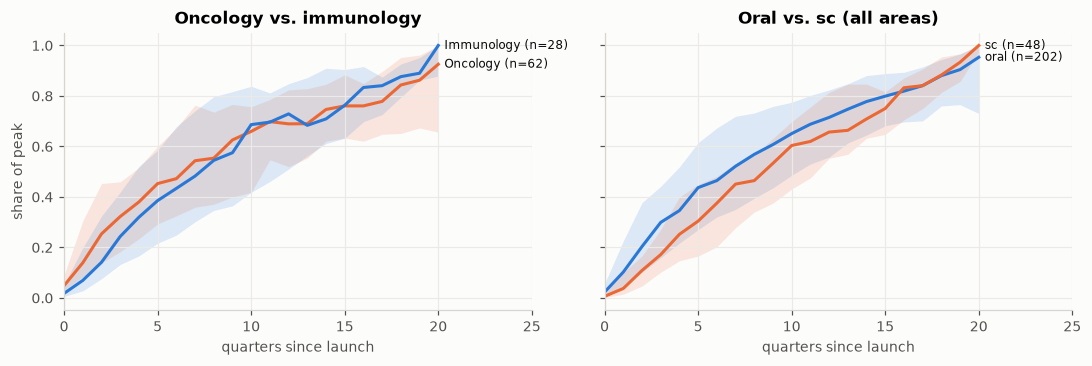

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (title, groups) in zip(axes, [
        ("Oncology vs. immunology", [("Oncology", u[u.area == "Oncology"], ORANGE), ("Immunology", u[u.area == "Immunology"], BLUE)]),
        ("Oral vs. sc (all areas)", [("oral", u[u.route_group == "oral"], BLUE), ("sc", u[u.route_group == "sc"], ORANGE)])]):
    for label, d, color in groups:
        b = band(d)
        ax.fill_between(b.index, b.q25, b.q75, color=color, alpha=0.15, lw=0)
        ax.plot(b.index, b["median"], color=color)
        ax.annotate(f"{label} (n={d.analog_id.nunique()})", (20, b["median"].iloc[-1]), xytext=(4, 0),
                    textcoords="offset points", va="center", color=INK, fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("quarters since launch")
    ax.set_xlim(0, 25)
axes[0].set_ylabel("share of peak")
plt.tight_layout()
plt.show()

**Speed to peak:** the first quarter each usable curve reaches 50% and 80% of its peak.

In [8]:
def first_q(c, level):
    hit = c[c.share_of_peak >= level]
    return hit.q_since_launch.min() if len(hit) else np.nan

speed = u.groupby("analog_id").apply(lambda c: pd.Series({"q50": first_q(c, 0.5), "q80": first_q(c, 0.8)}))
speed = speed.join(features.set_index("analog_id")[["area", "route_group", "peak_q"]])
speed[speed.area.isin(big)].groupby("area")[["q50", "q80", "peak_q"]].median().sort_values("q50")

,q50,q80,peak_q
area,,,
Anti-infectives,5.0,11.5,15.0
Respiratory,5.5,11.0,15.5
Alimentary & metabolism,6.0,13.0,18.0
Oncology,6.5,13.0,18.0
Nervous system,7.0,13.0,19.0
Blood,8.0,16.0,20.0
Cardiovascular,8.0,16.0,20.0
Immunology,8.0,12.0,17.0


## 3. Peak inside Q0–Q20: still climbing at Q20?

Only analogs with a full window (Q20 is a complete quarter) can be judged. If late climbs are enrollment-driven, curves whose Q16–Q20 falls in the COVID continuous-coverage period (2020Q2–2023Q1) should climb more at the end than curves whose window closed before 2020.

In [9]:
full = u.groupby("analog_id").q_since_launch.max()
full = full[full >= 20].index
fw = u[u.analog_id.isin(full)]
end = fw.pivot(index="analog_id", columns="q_since_launch", values="share_of_peak")
late = pd.DataFrame({"share_q16": end[16], "q20_period": fw[fw.q_since_launch == 20].set_index("analog_id").period})
late["peak_at_q20"] = end[20] >= 0.999
late["climb_q16_q20"] = end[20] - end[16]
covid = (qnum("2020Q2"), qnum("2023Q1"))
def window(p):
    q20 = qnum(p)
    if q20 < covid[0]:
        return "Q20 before COVID"
    return "Q16-Q20 overlaps COVID" if q20 - 4 <= covid[1] else "Q20 after COVID"
late["q20_window"] = late.q20_period.map(window)
late = late.join(features.set_index("analog_id")[["area", "approval_year"]])
print(f"{len(late)} usable analogs with a full Q0-Q20 window; {late.peak_at_q20.sum()} peak at Q20")
late.groupby("q20_window").agg(analogs=("peak_at_q20", "size"), pct_peak_at_q20=("peak_at_q20", lambda s: round(100 * s.mean())),
                               median_climb_q16_q20=("climb_q16_q20", "median"))

208 usable analogs with a full Q0-Q20 window; 89 peak at Q20


,analogs,pct_peak_at_q20,median_climb_q16_q20
q20_window,,,
Q16-Q20 overlaps COVID,89,43,0.1053
Q20 after COVID,37,46,0.1169
Q20 before COVID,82,41,0.1212


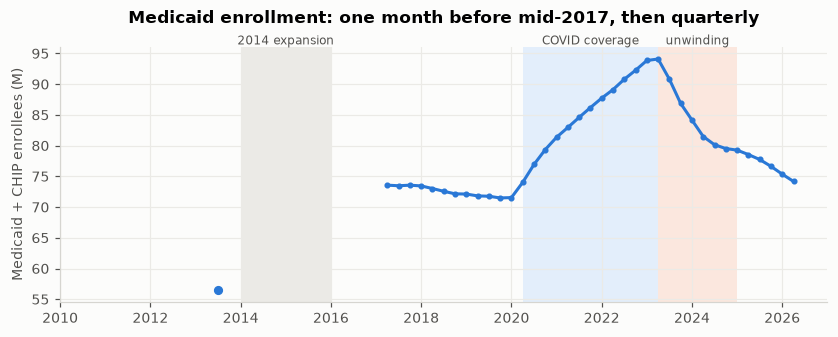

In [10]:
e = enroll.dropna(subset=["enrollees"]).copy()
e["t"] = e.period.map(lambda p: int(p[:4]) + (int(p[-1]) - 1) / 4)
fig, ax = plt.subplots(figsize=(9, 3))
for name, lo, hi, c in [("2014 expansion", "2014Q1", "2015Q4", "#ebeae6"),
                        ("COVID coverage", "2020Q2", "2023Q1", "#e3eefb"),
                        ("unwinding", "2023Q2", "2024Q4", "#fbe7de")]:
    x0, x1 = qnum(lo) / 4, (qnum(hi) + 1) / 4
    ax.axvspan(x0, x1, color=c, lw=0)
    ax.text((x0 + x1) / 2, 1.0, name, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8, color=INK2)
# 2013Q3 is a single baseline month; the series proper starts 2017Q2, so don't draw a line across the gap
monthly = e[e.t >= 2017]
ax.plot(monthly.t, monthly.enrollees / 1e6, color=BLUE, marker="o", ms=3)
ax.plot(e.t[e.t < 2017], e.enrollees[e.t < 2017] / 1e6, color=BLUE, marker="o", ms=5, ls="none")
ax.set_ylabel("Medicaid + CHIP enrollees (M)")
ax.set_xlim(2010, 2027)
ax.set_title("Medicaid enrollment: one month before mid-2017, then quarterly", pad=16)
plt.show()

The comparison is confounded by launch year (drugs whose Q20 falls in COVID launched 2015–2018), and by area mix. Look at it within area:

In [11]:
late[late.area.isin(["Oncology", "Immunology", "Nervous system", "Alimentary & metabolism"])].groupby(
    ["area", "q20_window"]).agg(analogs=("peak_at_q20", "size"), pct_peak_at_q20=("peak_at_q20", lambda s: round(100 * s.mean())),
                                median_climb=("climb_q16_q20", "median")).unstack("q20_window")

analogs                                         pct_peak_at_q20                                            median_climb                                 
q20_window              Q16-Q20 overlaps COVID Q20 after COVID Q20 before COVID Q16-Q20 overlaps COVID Q20 after COVID Q20 before COVID Q16-Q20 overlaps COVID Q20 after COVID Q20 before COVID
area                                                                                                                                                                                           
Alimentary & metabolism                     14               2               14                     36               0               43                0.06295        -0.03490          0.15095
Immunology                                   6               4                9                     83              25               44                0.37230         0.00715          0.12410
Nervous system                              13              10               10                     46              70               50                0.14920         0.13740          0.17795
Oncology                                    21              13               22                     29              31               41                0.09640         0.06230          0.12285

## 4. Bass fits

Cumulative Bass m·F(t) fitted to share of peak (decision 2026-10-22). `weak_fit_flag` = R² < 0.9 or a parameter on its bound; m above 1 means the curve was still climbing at the end of its data.

In [12]:
fb = fits.merge(features[["analog_id", "area", "route_group", "usable", "brand"]], on="analog_id")
fb = fb[fb.usable]
print(f"{len(fb)} usable analogs fitted; weak: {fb.weak_fit_flag.sum()}; m at the 5.0 cap: {(fb.m >= 4.99).sum()}")
fb.groupby("area").agg(n=("p", "size"), weak=("weak_fit_flag", "sum"), p_median=("p", "median"),
                       q_median=("q", "median"), m_median=("m", "median"), r2_median=("fit_quality", "median")
                       ).query("n >= 8").sort_values("q_median").round(3)

250 usable analogs fitted; weak: 100; m at the 5.0 cap: 27


,n,weak,p_median,q_median,m_median,r2_median
area,,,,,,
Respiratory,8,5,0.078,0.124,1.073,0.931
Anti-infectives,18,11,0.034,0.145,0.902,0.832
Blood,15,7,0.026,0.147,1.164,0.937
Immunology,28,9,0.020,0.154,1.058,0.970
Nervous system,41,7,0.032,0.167,1.023,0.980
Cardiovascular,13,1,0.021,0.169,1.313,0.989
Oncology,62,41,0.047,0.171,0.938,0.891
Alimentary & metabolism,34,10,0.024,0.269,1.011,0.943


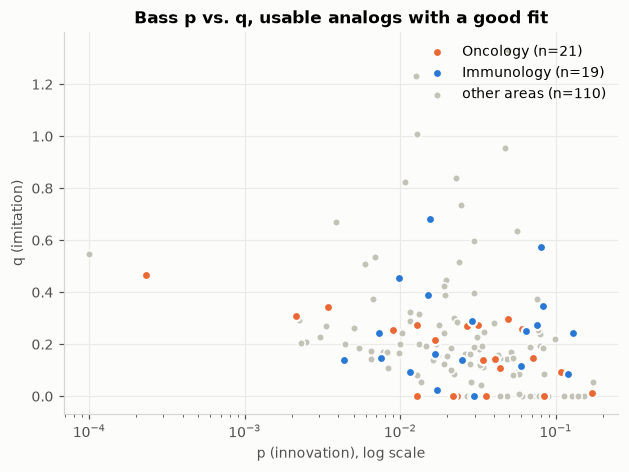

In [13]:
good = fb[~fb.weak_fit_flag]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, color in [("Oncology", ORANGE), ("Immunology", BLUE)]:
    d = good[good.area == name]
    ax.scatter(d.p, d.q, s=36, color=color, edgecolor="#fcfcfb", lw=1.5, label=f"{name} (n={len(d)})", zorder=3)
rest = good[~good.area.isin(["Oncology", "Immunology"])]
ax.scatter(rest.p, rest.q, s=24, color="#c3c2b7", edgecolor="#fcfcfb", lw=1, label=f"other areas (n={len(rest)})", zorder=2)
ax.set_xscale("log")
ax.set_xlabel("p (innovation), log scale")
ax.set_ylabel("q (imitation)")
ax.set_title("Bass p vs. q, usable analogs with a good fit")
ax.legend(loc="upper right")
plt.show()

Weak fits: which kind are they? Low R² (rise-and-fall curves) vs. a parameter on a bound (often m, for curves still climbing).

In [14]:
weak = fb[fb.weak_fit_flag].copy()
weak["why"] = np.where(weak.fit_quality < 0.9, "R2 < 0.9", "parameter on bound")
print(weak.why.value_counts().to_string())
weak.sort_values("fit_quality")[["analog_id", "area", "p", "q", "m", "fit_quality", "why"]].head(12)

why
R2 < 0.9              77
parameter on bound    23


,analog_id,area,p,q,m,fit_quality,why
249,zepatier_oral,Anti-infectives,0.03210,0.0000,0.500,-0.3610,R2 < 0.9
195,symdeko_oral,Respiratory,0.07701,2.0000,0.500,-0.0431,R2 < 0.9
243,xofluza_oral,Anti-infectives,0.03534,0.0000,0.500,0.0040,R2 < 0.9
28,caprelsa_oral,Oncology,0.25679,0.0000,0.500,0.0097,R2 < 0.9
78,harvoni_oral,Anti-infectives,0.19714,2.0000,0.500,0.0183,R2 < 0.9
14,baxdela_oral,Anti-infectives,0.02799,2.0000,0.500,0.0346,R2 < 0.9
153,pemazyre_oral,Oncology,0.08646,2.0000,0.702,0.0380,R2 < 0.9
35,cotellic_oral,Oncology,0.24103,1.1380,0.645,0.0456,R2 < 0.9
29,carbaglu_oral,Alimentary & metabolism,0.04087,2.0000,0.630,0.0964,R2 < 0.9
159,potiga_oral,Nervous system,0.11897,2.0000,0.500,0.0983,R2 < 0.9


## 5. Distortion flags in the usable pool

The flags aren't filters yet. How common are they, and does a possible label expansion in Q0–Q12 change the curve?

In [15]:
uf = features[features.usable]
pd.Series({
    "label_expansion_in_window": uf.label_expansion_in_window.mean(),
    "any enrollment shock in Q0-Q12": uf.enrollment_shock_in_window.notna().mean(),
    "multi_route": uf.multi_route.mean(),
    "peak_at_last_quarter": uf.peak_at_last_quarter.mean(),
    "suppressed_quarters > 0": (uf.suppressed_quarters > 0).mean(),
}).mul(100).round().rename("% of usable analogs")

label_expansion_in_window         55.0
any enrollment shock in Q0-Q12    91.0
multi_route                        6.0
peak_at_last_quarter              48.0
suppressed_quarters > 0           94.0
Name: % of usable analogs, dtype: float64

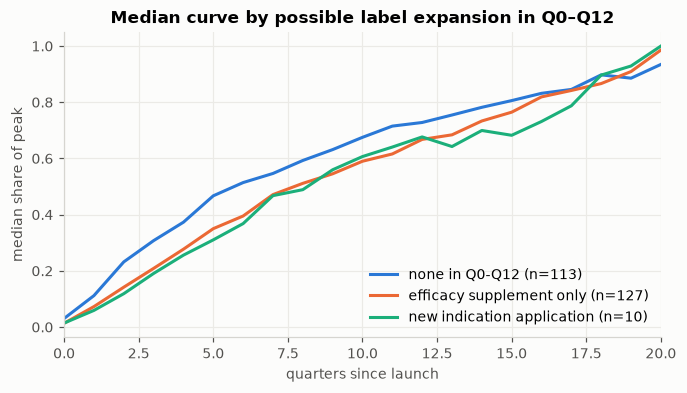

In [16]:
# Separate real expansions (new-indication applications) from efficacy supplements, which only *may* add one
h = history[(history.kind != "original") & history.q_since_launch.between(0, 12)]
kinds = h.groupby("analog_id").kind.agg(lambda s: "new indication application" if (s == "new indication application").any() else "efficacy supplement only")
u2 = u.copy()
u2["expansion"] = u2.analog_id.map(kinds).fillna("none in Q0-Q12")

fig, ax = plt.subplots(figsize=(7, 3.6))
for label, color in [("none in Q0-Q12", BLUE), ("efficacy supplement only", ORANGE), ("new indication application", AQUA)]:
    d = u2[u2.expansion == label]
    b = band(d)
    ax.plot(b.index, b["median"], color=color, label=f"{label} (n={d.analog_id.nunique()})")
ax.legend(loc="lower right")
ax.set_xlim(0, 20)
ax.set_xlabel("quarters since launch")
ax.set_ylabel("median share of peak")
ax.set_title("Median curve by possible label expansion in Q0–Q12")
plt.show()

## 6. Seed brands

The prototype analogs: six plaque psoriasis biologics/orals and Otezla (psoriatic arthritis first), plus Ibrance (oncology). Raw Medicaid TRx, then share of peak.

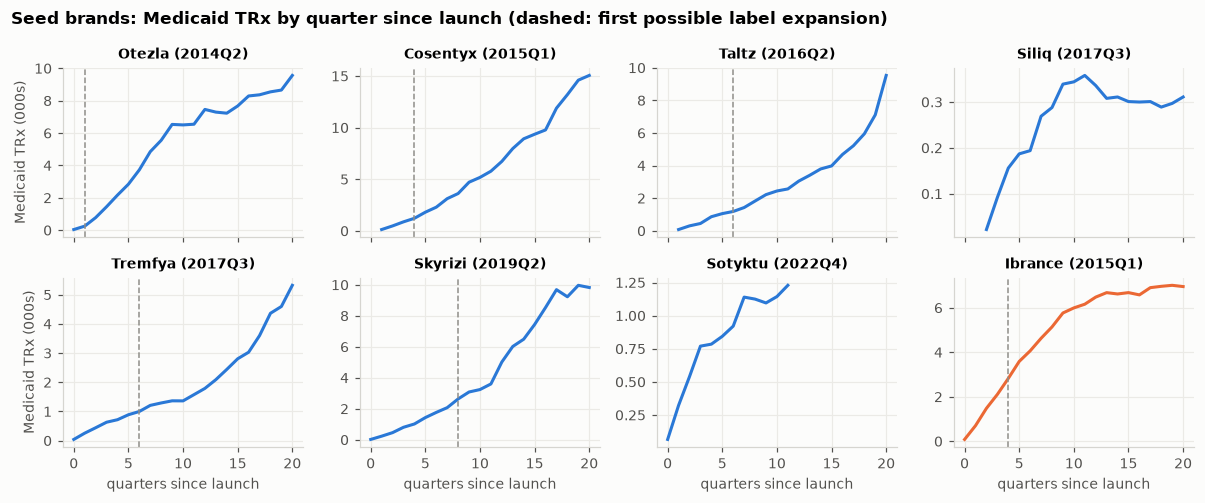

In [17]:
seed = ["otezla_oral", "cosentyx_sc", "taltz_sc", "siliq_sc", "tremfya_sc", "skyrizi_sc", "sotyktu_oral", "ibrance_oral"]
sc_ = curves[curves.analog_id.isin(seed) & ~curves.provisional]
fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharex=True)
for ax, aid in zip(axes.flat, seed):
    c = sc_[sc_.analog_id == aid]
    ax.plot(c.q_since_launch, c.trx / 1000, color=ORANGE if aid == "ibrance_oral" else BLUE)
    exp = c[c.label_expansion_flag]
    if len(exp):
        ax.axvline(exp.q_since_launch.min(), color=GRAY, lw=1, ls="--")
    ax.set_title(f"{a.loc[aid, 'brand name']} ({c.period.iloc[0]})", fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("quarters since launch")
for ax in axes[:, 0]:
    ax.set_ylabel("Medicaid TRx (000s)")
fig.suptitle("Seed brands: Medicaid TRx by quarter since launch (dashed: first possible label expansion)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

In [18]:
fits.merge(features[["analog_id", "launch_quarter", "peak_q", "peak_at_last_quarter", "late_launch"]], on="analog_id"
           ).set_index("analog_id").loc[[s for s in seed if s in set(fits.analog_id)],
                                        ["launch_quarter", "p", "q", "m", "fit_quality", "weak_fit_flag", "peak_q", "peak_at_last_quarter"]]

,launch_quarter,p,q,m,fit_quality,weak_fit_flag,peak_q,peak_at_last_quarter
analog_id,,,,,,,,
otezla_oral,2014Q2,0.02888,0.2884,0.911,0.9833,False,20.0,True
cosentyx_sc,2015Q1,0.00753,0.1454,1.876,0.9950,False,20.0,True
taltz_sc,2016Q2,0.00188,0.1294,5.000,0.9722,True,20.0,True
siliq_sc,2017Q3,0.01550,0.6835,0.883,0.9344,False,11.0,False
tremfya_sc,2017Q3,0.00270,0.1118,5.000,0.9823,True,20.0,True
skyrizi_sc,2019Q2,0.00729,0.2424,1.227,0.9905,False,19.0,False
sotyktu_oral,2022Q4,0.12948,0.2419,0.996,0.9701,False,11.0,True
ibrance_oral,2015Q1,0.04913,0.2960,0.992,0.9972,False,19.0,False


## Takeaways

*From the committed tables as of 2026-10-23 (`main` at `1bc6134`, after the ATC class fix). The numbers are typed in here, so update them when the tables are rebuilt.*

**Pool and survivorship**
- 250 of 426 analogs are usable. Of the 176 left out, 94 are recent launches (< 12 quarters), 43 have a blank quarter after Q2, 20 have no Medicaid Rx and 19 launched late. Approvals from 2023 on are almost all out for now (too few quarters).
- The blank-quarter dropouts are tiny brands: median 442 total Medicaid Rx vs. 34,367 for usable analogs. The usable pool is the bigger launches, so its curves describe brands that got traction in Medicaid.
- Oncology (62 usable) is the largest area, then nervous system (41) and alimentary & metabolism (34). Immunology has 28, about half sc.
- **Partial suppression is almost everywhere:** 94% of usable analogs have at least one quarter with a suppressed row (often a small package NDC). That quarter's TRx is the sum of the visible rows, a small undercount.

**Curve shape**
- Median time to 50% of the Q0–Q20 peak is 5–8 quarters in every large area, and 80% takes 11–16. Areas differ less than the prototype suggested.
- Oncology rises faster early, while immunology starts slower and catches up by about Q10. Oncology's median ends below 1.0 at Q20 (many curves peak earlier and decline); immunology's is still climbing.
- sc launches start slower than oral (about 0.30 vs. 0.44 of peak at Q5) and converge by Q16.

**Peak at Q20**
- 89 of the 208 usable analogs with a full window peak at Q20 (43%).
- Overall there's no COVID signal. Curves whose Q16–Q20 overlaps COVID continuous coverage peak at Q20 as often (43%) as those whose Q20 came before COVID (41%) or after it (46%), and climb about as much from Q16 to Q20.
- **Immunology is the exception:** 5 of 6 (83%) overlapping COVID peak at Q20, vs. 4 of 9 before COVID, with a median Q16–Q20 climb of 0.37 vs. 0.12. That fits Taltz and Tremfya, but n = 6, so treat it as a lead, not a result.

**Bass fits**
- 100 of 250 usable fits are weak: 77 with R² < 0.9 (rise-and-fall curves such as the hepatitis C cures, Xofluza, Caprelsa) and 23 with a parameter on a bound. 27 have m at the 5.0 cap (still climbing).
- **Oncology is the problem area:** 41 of 62 fits are weak (median R² 0.89), against 9 of 28 in immunology. A cumulative Bass curve doesn't fit oncology's rise-plateau-decline shape well, so the oncology p and q are less trustworthy.
- Median q ranges from 0.12 (respiratory, 8 analogs) to 0.27 (alimentary & metabolism). Respiratory has the highest median p (0.078), then oncology (0.047), i.e. a faster start.

**Distortion flags**
- `enrollment_shock_in_window` is on for 91% of usable analogs and `label_expansion_in_window` for 55%, so neither separates analogs as it stands.
- Curves with no possible expansion in Q0–Q12 are front-loaded (0.47 of peak at Q5, vs. 0.35 with an efficacy supplement and 0.31 with a new-indication application): expansions push the peak later, as expected. Efficacy-supplement-only curves look like new-indication-application curves, so many supplements may be real expansions. The approval-letter read would settle it.

**Seed brands**
- Otezla, Cosentyx, Taltz and Tremfya all peak at Q20. Taltz and Tremfya have m at the cap (weak fits), so their p and q aren't identified from Q0–Q20.
- Siliq peaks at Q11 with a high q (0.68) and very small volume (peak about 360 TRx a quarter; launched with a REMS), unlike the other IL-17/23 drugs. Its first two quarters are blank (suppressed).
- Ibrance plateaus from about Q12, the oncology shape.

**Next questions**
1. Check the immunology COVID effect with more analogs, or with enrollment-adjusted curves from 2017Q2 on.
2. Try Bass on new adopters, or another curve form, for oncology before relying on its p and q.
3. Measure how much partial suppression undercounts TRx (share of suppressed rows per quarter).
4. Re-run once clinic-administered sc drugs are flagged: they're still in the sc numbers here.